In [3]:
import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

In [ ]:
CSV_PATH = "/kaggle/input/sdfghj/clean_dataset.csv"     
OUTPUT_DIR = "cnn_lstm_model"       
WINDOW_SIZE = 10                  
EPOCHS = 50
BATCH_SIZE = 32
TEST_SPLIT = 0.15
VAL_SPLIT = 0.15
RANDOM_SEED = 42

In [ ]:
FEATURES = [
    "open","high","low","volume","market_cap","url_shares","unique_url_shares",
    "reddit_posts","reddit_posts_score","reddit_comments","reddit_comments_score",
    "tweets","tweet_spam","tweet_followers","tweet_quotes","tweet_retweets",
    "tweet_replies","tweet_favorites","tweet_sentiment1","tweet_sentiment2",
    "tweet_sentiment3","tweet_sentiment4","tweet_sentiment5",
    "tweet_sentiment_impact1","tweet_sentiment_impact2","tweet_sentiment_impact3",
    "tweet_sentiment_impact4","tweet_sentiment_impact5","social_score",
    "average_sentiment","news","price_score","social_impact_score",
    "correlation_rank","galaxy_score","volatility","market_cap_rank",
    "percent_change_24h_rank","volume_24h_rank","social_volume_24h_rank",
    "social_score_24h_rank","medium","youtube","social_volume",
    "percent_change_24h","market_cap_global"
]
TARGET = "close"

In [ ]:
def create_sequences(X, y, window_size):
    """Convert data to sequential format for LSTM"""
    Xs, ys = [], []
    for i in range(len(X) - window_size):
        Xs.append(X[i:i + window_size])
        ys.append(y[i + window_size])
    return np.array(Xs), np.array(ys)

In [ ]:
def build_cnn_lstm(input_shape):
    """Define CNN + LSTM model"""
    model = Sequential([
        Conv1D(64, 3, activation='relu', input_shape=input_shape),
        MaxPooling1D(2),
        Dropout(0.2),
        Conv1D(32, 3, activation='relu'),
        MaxPooling1D(2),
        Dropout(0.2),
        LSTM(64, return_sequences=False),
        Dropout(0.2),
        Dense(32, activation='relu'),
        Dense(1, activation='linear')
    ])
    model.compile(optimizer='adam', loss='mse', metrics=['mae'])
    return model

In [ ]:
df = pd.read_csv(CSV_PATH)
df = df.dropna(subset=[TARGET])
df[FEATURES] = df[FEATURES].fillna(df[FEATURES].median())

X = df[FEATURES].values
y = df[[TARGET]].values

x_scaler = MinMaxScaler()
y_scaler = MinMaxScaler()

X_scaled = x_scaler.fit_transform(X)
y_scaled = y_scaler.fit_transform(y)

X_seq, y_seq = create_sequences(X_scaled, y_scaled, WINDOW_SIZE)

In [ ]:
train_size = int(len(X_seq) * (1 - TEST_SPLIT - VAL_SPLIT))
val_size = int(len(X_seq) * VAL_SPLIT)

X_train, y_train = X_seq[:train_size], y_seq[:train_size]
X_val, y_val = X_seq[train_size:train_size + val_size], y_seq[train_size:train_size + val_size]
X_test, y_test = X_seq[train_size + val_size:], y_seq[train_size + val_size:]

In [ ]:
model = build_cnn_lstm((X_train.shape[1], X_train.shape[2]))

os.makedirs(OUTPUT_DIR, exist_ok=True)

callbacks = [
    EarlyStopping(patience=8, restore_best_weights=True, monitor='val_loss'),
    ModelCheckpoint(os.path.join(OUTPUT_DIR, "best_model.h5"), save_best_only=True, monitor='val_loss'),
    ReduceLROnPlateau(patience=4, factor=0.5, monitor='val_loss')
]

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks,
    verbose=1
)

In [ ]:
y_pred = model.predict(X_test)
y_true = y_scaler.inverse_transform(y_test)
y_pred_inv = y_scaler.inverse_transform(y_pred)

mae = mean_absolute_error(y_true, y_pred_inv)
mse = mean_squared_error(y_true, y_pred_inv)
rmse = np.sqrt(mse)
r2 = r2_score(y_true, y_pred_inv)

In [ ]:
print("\n Model Performance on Test Set:")
print(f"MAE  = {mae:.4f}")
print(f"MSE  = {mse:.4f}")
print(f"RMSE = {rmse:.4f}")
print(f"R²   = {r2:.4f}")

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title("Training vs Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss (MSE)")
plt.legend()
plt.tight_layout()
plt.show()

2025-10-11 08:34:39.585278: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1760171679.807581      37 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1760171679.872931      37 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
2025-10-11 08:34:53.999379: E external/local_xla/xla/stream_executor/cuda/cuda_driver.cc:152

Epoch 1/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - loss: 0.0401 - mae: 0.1153 - val_loss: 0.0334 - val_mae: 0.1045 - learning_rate: 0.0010
Epoch 2/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0376 - mae: 0.1145 - val_loss: 0.0333 - val_mae: 0.1068 - learning_rate: 0.0010
Epoch 3/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0357 - mae: 0.1127 - val_loss: 0.0337 - val_mae: 0.1239 - learning_rate: 0.0010
Epoch 4/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0389 - mae: 0.1222 - val_loss: 0.0339 - val_mae: 0.0982 - learning_rate: 0.0010
Epoch 5/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0426 - mae: 0.1259 - val_loss: 0.0332 - val_mae: 0.1077 - learning_rate: 0.0010
Epoch 6/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0329 - mae: 0.1071 - val_loss: 0.0330 - val_mae: 0.1109 - learning_rate: 0.0010
Epoch 7/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0362 - mae: 0.1186 - val_loss: 0.0332 - val_mae: 0.1167 - learning_rate: 0.0010
Epoch 8/50
51/51 ━━

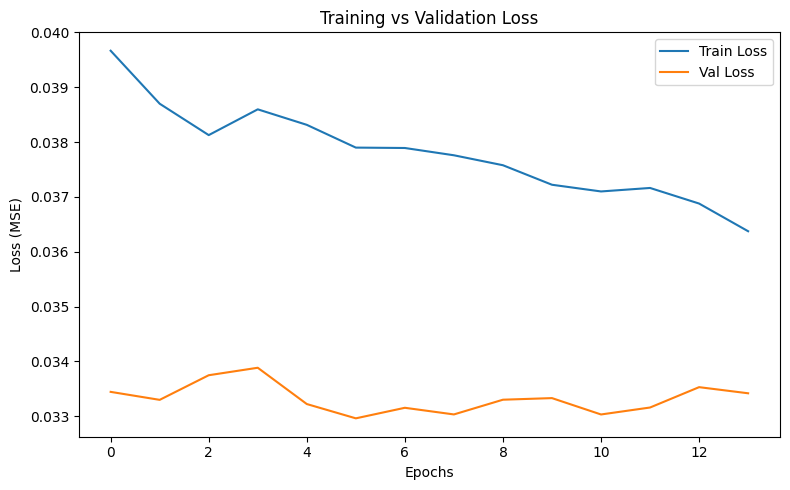


 Model and artifacts saved in 'cnn_lstm_model' folder.


In [ ]:
model.save(os.path.join(OUTPUT_DIR, "final_cnn_lstm_model.h5"))
joblib.dump(x_scaler, os.path.join(OUTPUT_DIR, "x_scaler.pkl"))
joblib.dump(y_scaler, os.path.join(OUTPUT_DIR, "y_scaler.pkl"))
with open(os.path.join(OUTPUT_DIR, "meta.json"), "w") as f:
    json.dump({"features": FEATURES, "target": TARGET, "window_size": WINDOW_SIZE}, f)

print(f"\n Model and artifacts saved in '{OUTPUT_DIR}' folder.")

In [2]:
!pip list

Package                               Version             Editable project location
------------------------------------- ------------------- -------------------------
absl-py                               1.4.0
absolufy-imports                      0.3.1
accelerate                            1.9.0
aiofiles                              22.1.0
aiohappyeyeballs                      2.6.1
aiohttp                               3.12.15
aiosignal                             1.4.0
aiosqlite                             0.21.0
alabaster                             1.0.0
albucore                              0.0.24
albumentations                        2.0.8
ale-py                                0.11.2
alembic                               1.16.5
altair                                5.5.0
annotated-types                       0.7.0
annoy                                 1.17.3
ansicolors                            1.1.8
antlr4-python3-runtime                4.9.3
anyio                           